# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 2: Red neuronal con dos capas ocultas

**Grupo:** 2

**Integrantes:**
- Alondra Estay
- Gaspar Galaz
- José Mora
- Renato Reyes

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). 
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)   # aquí se guardan las figuras para el informe

## Datos

Los archivos `datos_P2.csv` (partes (c) a (f)) y `datos_P2_g.csv` (parte (g)) deben estar en la misma carpeta que este notebook. Tienen una línea de encabezado `x,y` y dos columnas separadas por comas.

N = 200 datos;  x en [-0.990, 0.966],  y en [-0.077, 2.216]


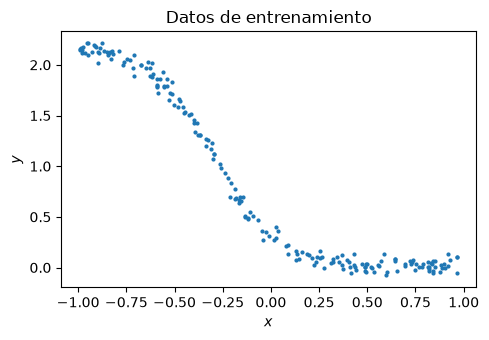

In [2]:
x, y = np.loadtxt("datos_P2.csv", delimiter=",", skiprows=1, unpack=True)
x_g, y_g = np.loadtxt("datos_P2_g.csv", delimiter=",", skiprows=1, unpack=True)
N = len(x)
print(f"N = {N} datos;  x en [{x.min():.3f}, {x.max():.3f}],  y en [{y.min():.3f}, {y.max():.3f}]")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, y, ".", ms=4)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Datos de entrenamiento")
fig.tight_layout()
fig.savefig("figuras/datos_P2.png", dpi=200)
plt.show()

## Notación

Los parámetros se agrupan, en este orden, en el vector $\theta = (a_1, b_1, a_2, b_2, v, c) \in \mathbb{R}^6$.

## (a) 

$$
\sigma(t)=\frac{1}{1+e^{-t}} = (1+e^{-t})^{-1}
$$
**derivamos con regla de la cadena:**
$$
\sigma'(t)=-(1+e^{-t})^{-2}(-e^{-t}) = \frac{e^{-t}}{(1+e^{-t})^{2}}
$$
**comprobamos si se satisface σ′(t) = σ(t)(1 − σ(t))**
$$
\sigma(t)(1-\sigma(t))\;=\; (\frac{1}{1+e^{-t}})(1 - \frac{1}{1+e^{-t}}) \;=\; \frac{1}{1+e^{-t}} - \frac{1}{(1+e^{-t})^2} \;=\; \frac{1 + e^{-t} - 1}{(1+e^{-t})^2} \;=\; \frac{e^{-t}}{(1+e^{-t})^2} \;=\; \sigma'(t)
$$
**deducimos que 0 < σ′(t), debido a que:**
$$
\forall t \in \mathbb{R}, \quad (e^{-t} > 0)
$$

**Luego:**
$$
(\sigma(t) - \frac{1}{2})^2 \geq 0 \quad \Rightarrow \quad \sigma^2(t) - \sigma(t) + \frac{1}{4} \geq 0 \quad\Rightarrow\quad \sigma(t) - \sigma^2(t) \leq \frac{1}{4} \quad\Rightarrow \quad\sigma(t)(1-\sigma(t)) \leq \frac{1}{4} \quad\Rightarrow \quad \sigma'(t) \leq \frac{1}{4}
$$
**Por lo que se deduce que 0 < σ′(t) ≤ ¼**

**Para encontrar el máximo de σ′(t) podemos usar σ′′(t) = 0, por regla de la cadena tenemos que:**
$$
\sigma''(t) = \frac{-e^{-t}(1+e^{-t})^2 - 2(1+e^{-t})(-e^{-t})(e^{-t})}{(1+e^{-t})^4}=\frac{-e^{-t}(1+e^{-t})-2(-e^{-t})(e^{-t})}{(1+e^{-t})^3} = \frac{-e^{-t}-e^{-2t}+2e^{-2t}}{(1+e^{-t})^3}=\frac{e^{-2t}-e^{-t}}{(1+e^{-t})^3} = \frac{e^{-t}(e^{-t}-1)}{(1+e^{-t})^3}
$$
**Buscamos punto crítico:**
$$
\frac{e^{-t}(e^{-t}-1)}{(1+e^{-t})^3} = 0 \quad\Rightarrow\quad(e^{-t}-1) = 0 \quad\Rightarrow\quad e^{-t} = 1 \quad\Rightarrow\quad t = 0
$$
**notamos que si t > 0 → σ′′(t) < 0 y si t < 0 → σ′′(t) > 0, por lo que σ′(t) tiene un máximo en t = 0**
$$
\sigma'(0) = \frac{e^{0}}{(1+e^{0})^{2}} = \frac{1}{4}
$$


## (b)
#### **definir:**
$$ 
z_{1,i} = a_1x_i+b1, \quad h_{1,i} = \sigma(z_1,i), \quad z_{2,i}=a_2h_{1,i}+b_2, \quad h_{2,i}=\sigma(z_{2,i}), \quad \hat{y}_i=c+vh_{2,i}, \quad e_i=\hat{y}_i-y_i, \quad L_i = \frac{e^2_i}{2}\\
\sigma'(t) = \sigma(t)(1- \sigma(t))\\
\theta = (a_1, b_1, a_2, b_2, v, c)\\
L_i = \frac{e^2_i}{2}
$$
**Funcion pérdida:**
$$
J(\theta) = \frac{1}{2N}\sum_{i=1}^{N}(\hat{y}_i - y_i)^2\quad=\quad\frac{1}{2N}\sum_{i=1}^{N}(e_i)^2 = \frac{1}{N}\sum_{i=1}^{N}Li
$$
#### **6 Derivadas parciales:**

**1°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2)-y_i)^2 \quad\Rightarrow\quad\frac{\partial L_i}{\partial a_1} = (c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2)-y_i)(a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) \cdot x_i) \\= (e_i \cdot a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) \cdot x_i) = (e_i \cdot a_2\cdot v \cdot h_{2,i}(1 - h_{2,i}) \cdot h_{1,i}(1-h_{1,i}) \cdot x_i)
$$

**2°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2) -y_i)^2 \quad\Rightarrow\quad\frac{\partial L_i}{\partial b_1} = (c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2) -y_i)(a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i})) \\= e_i \cdot a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) = e_i \cdot a_2\cdot v \cdot h_{2,i}(1 - h_{2,i}) \cdot h_{1,i}(1-h_{1,i})
$$

**3°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2h_{1,i}+b_2) -y_i)^2\quad\Rightarrow\quad\frac{\partial L_i}{\partial a_2} = (c+v\sigma(a_2h_{1,i}+b_2) -y_i)(h_{1,i}\cdot v \cdot \sigma'(z_{2,i}))\\
 = (e_i \cdot h_{1,i}\cdot v \cdot \sigma'(z_{2,i})) = (e_i \cdot h_{1,i}\cdot v \cdot h_{2,i}(1-h_{2,i}))
$$

**4°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2h_{1,i}+b_2) -y_i)^2\quad\Rightarrow\quad\frac{\partial L_i}{\partial b_2} = (c+v\sigma(a_2h_{1,i}+b_2)-y_i)(v \cdot \sigma'(z_{2,i}))\\=(e_i\cdot v \cdot \sigma'(z_{2,i}))=(e_i \cdot v \cdot h_{2,i}(1-h_{2,i}))
$$

**5°**
$$
L_i = \frac{1}{2}(c+v \cdot h_{2,i} - y_i)^2 \quad\Rightarrow\quad \frac{\partial L_i}{\partial v} = ((c+v \cdot h_{2,i} - y_i)h_{2,i})\;=\:(e_i \cdot h_{2,i})
$$

**6°**
$$
L_i = \frac{1}{2}(c+v \cdot h_{2,i} - y_i)^2 \quad\Rightarrow\quad \frac{\partial L_i}{\partial c} = (c+v \cdot h_{2,i} - y_i)\;=\;(e_i)
$$
**factores repetidos**
$$
\varphi _{2,i} = e_i \cdot v \cdot h_{2,i}(1-h_{2,i}) ,\quad \varphi _{1,i} = \varphi _{2,i} \cdot h_{1,i}(1-h_{1,i}) \cdot a_2
$$
**gradiente de forma completa**
$$
\nabla _\theta J(\theta) = \frac{1}{N}\sum_{i=1}^{N}        \begin{pmatrix}
\varphi _{1,i}x_i \\
\varphi _{1,i} \\
\varphi _{2,i}h_{1,i} \\
\varphi _{2,i} \\
e_ih_{2,i} \\
e_i
\end{pmatrix}
$$

## (c) Implementación y verificación del gradiente

In [3]:
theta_forma = ("a_1", "b_1", "a_2", "b_2", "v", "c")
def sigma(t):
    return 1/(1+np.exp(-t))
def h_1(i, theta, x):
    return sigma(theta[1] + theta[0] * x[i])
def h_2(i, theta, x):
    return sigma(theta[3] + theta[2] * h_1(i, theta, x))
def phi_2(i, theta, x, y):
    return (theta[5] + theta[4] * h_2(i, theta, x) - y[i]) * theta[4] * h_2(i, theta, x) * (1 - h_2(i, theta, x)) 
def phi_1(i, theta, x, y):
    return phi_2(i, theta, x, y) * h_1(i, theta, x) * (1 - h_1(i,theta, x)) * theta[2]
def e(i, theta, x, y):
    return theta[5] + theta[4] * h_2(i, theta, x) - y[i]

def J(theta, x, y):
    i = np.arange(0, N)
    return sum(e(i, theta, x, y)**2)/(2*N)

def  dJ(theta, x, y):
    i = np.arange(0, N)
    return np.sum(np.array([
        phi_1(i, theta, x, y) * x[i], phi_1(i, theta, x, y), phi_2(i, theta, x, y)*h_1(i,theta, x), phi_2(i, theta, x, y), e(i, theta, x, y) * h_2(i, theta, x), e(i, theta, x, y)]), axis=1)/N



In [11]:
#Elegimos un theta cero aleatorio
theta_0 = np.random.uniform(-1, 1, 6)
print(theta_0)

[-0.28824117 -0.08699002 -0.91449653 -0.6212921   0.11734601 -0.07469821]


In [14]:
#Guardamos un theta cero
canon = np.array([[1, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0], [0, 0, 0, 1, 0, 0], [0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1]])
theta_0 = np.array([-0.28824117, -0.08699002, -0.91449653, -0.6212921, 0.11734601, -0.07469821])
print(theta_0)

[-0.28824117 -0.08699002 -0.91449653 -0.6212921   0.11734601 -0.07469821]


In [18]:
print(J(theta_0, x, y))

0.7848795168338227


In [16]:
def funcion_b(i, theta, x, y, canon):
    return (J((theta_0 + (10**-5) * canon[i]), x, y) - J((theta_0 - (10**-5) * canon[i]), x, y)) / (2 * (10**-5))

errores = []
for i in range(6):
    errorabs = np.abs(dJ(theta_0, x, y)[i] - funcion_b(i, theta_0, x, y, canon))
    errores.append(errorabs)
    print("Funcion dJ:", dJ(theta_0, x, y)[i],  "|Funcion b:", funcion_b(i, theta_0, x, y, canon), "|Error absoluto:", errorabs)

Funcion dJ: -0.0026258517904793077 |Funcion b: -0.0026258517638044765 |Error absoluto: 2.66748311807119e-11
Funcion dJ: 0.004549815702081103 |Funcion b: 0.004549815707521887 |Error absoluto: 5.440784107968444e-12
Funcion dJ: -0.010386437061780827 |Funcion b: -0.010386437077070099 |Error absoluto: 1.5289271584895125e-11
Funcion dJ: -0.019980829651771843 |Funcion b: -0.019980829651933263 |Error absoluto: 1.6141948888659385e-13
Funcion dJ: -0.22715555677865085 |Funcion b: -0.22715555679786445 |Error absoluto: 1.9213602930889806e-11
Funcion dJ: -0.9073814595001838 |Funcion b: -0.9073814595084161 |Error absoluto: 8.232303727595536e-12


In [17]:
i = np.argmax(errores)
print("componente:", theta_forma[i], "Máximo Error:", errores[i])
#Máximo error absoluto

componente: a_1 Máximo Error: 2.66748311807119e-11


## (d) Descenso del gradiente

Definimos una función que nos permita cálcular el valor de theta k

In [6]:
def des_gradiente(theta, k, paso, x, y):
    theta_kmin1 = theta
    theta_k = [0, 0, 0, 0, 0, 0]
    for largo in range(k):
        theta_temp = dJ(theta_kmin1, x, y)
        for i in range(0, 6):
            #dado que el paso α = 1 no es necesario múltiplicar theta_kmin1
            theta_k[i] = theta_kmin1[i] - paso * theta_temp[i]
        theta_kmin1 = theta_k
    return theta_k

Definimos una función diferente que se encarge de calcular el error de cada iteración para graficarlo con facilidad

In [23]:
def des_gradiente_evo_error(theta, k, paso, x, y):
    theta_kmin1 = theta
    theta_k = [0, 0, 0, 0, 0, 0]
    errores = []
    for largo in range(k):
        theta_temp = dJ(theta_kmin1, x, y)
        for i in range(0, 6):
            theta_k[i] = theta_kmin1[i] - paso * theta_temp[i]
        theta_kmin1 = theta_k
        errores.append(J(theta_kmin1, x, y))
    return np.array(errores)

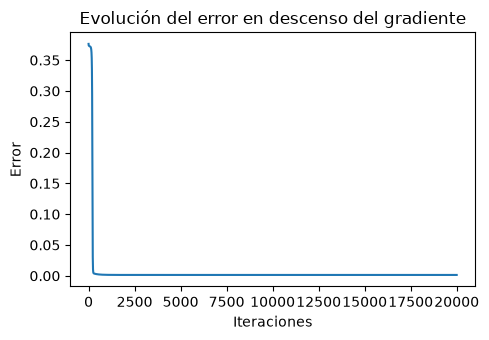

In [24]:
errores = des_gradiente_evo_error(theta_0, 20000, 1, x, y)
iteracion = np.arange(20000)


fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(iteracion, errores, "-", ms=4)
ax.set_xlabel("Iteraciones")
ax.set_ylabel("Error")
ax.set_title("Evolución del error en descenso del gradiente")
fig.tight_layout()
fig.savefig("figuras/evo_des_gradiente.png", dpi=200)
plt.show()

Reducimos el tamaño del grafico para visualizar el cambio en el error

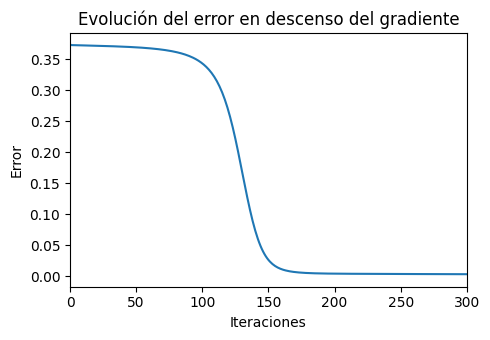

In [10]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(iteracion, errores, "-", ms=4)
ax.set_xlim(0, 300)
ax.set_xlabel("Iteraciones")
ax.set_ylabel("Error")
ax.set_title("Evolución del error en descenso del gradiente")
fig.tight_layout()
fig.savefig("figuras/evo_des_gradiente_cambio.png", dpi=200)
plt.show()

## (e) Parámetros encontrados

Los valores encontrados son:

In [11]:
val_20000 = des_gradiente(theta_0, 20000, 1, x, y)
print("θ20.000 es igual a:", val_20000)
print("El error J(θ20.000) es igual a:", J(val_20000, x, y))

θ20.000 es igual a: [np.float64(4.82070175710775), np.float64(0.680190806366675), np.float64(-4.054068759861999), np.float64(0.6141261364555466), np.float64(3.5773664096641298), np.float64(-0.10006448173910788)]
El error J(θ20.000) es igual a: 0.0013927707069917585


Escribimos una función para calcular ˆy(x;θ20.000)

In [12]:
def y_gorrito (i, theta, x):
    return theta[5] + theta[4] * h_2(i, theta, x)

In [13]:
aproximaciones = []
for i in range(N):
    aproximaciones.append(y_gorrito(i, val_20000, x))
aproximaciones = np.array(aproximaciones)

Text(0.5, 1.0, 'Comparación original y aproximación')

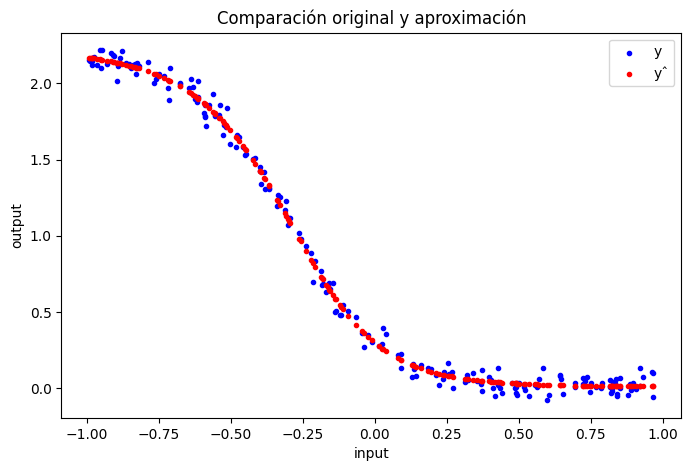

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(x, y, color='blue', marker='.', label='y')
plt.scatter(x, aproximaciones, marker='.', color='red', label='yˆ')

plt.legend()

plt.xlabel("input")
plt.ylabel("output")

plt.savefig("figuras/entrenamientoXcurva.png", dpi=200)
plt.title("Comparación original y aproximación")

## (f) Sensibilidad del entrenamiento

### i. Tamaño del paso

Repetimos (d)

In [ ]:
#import para evitar casilla salida roja
#import warnings
#warnings.filterwarnings('ignore')

error_001 = des_gradiente_evo_error(theta_0, 20000, 0.01, x, y)
error_01 = des_gradiente_evo_error(theta_0, 20000, 0.1, x, y)
#El paso igual a 1 ya lo calculamos antes
error_1 = errores
error_25 = des_gradiente_evo_error(theta_0, 20000, 2.5, x, y)

Text(0.5, 1.0, 'Cuatro pasos diferentes')

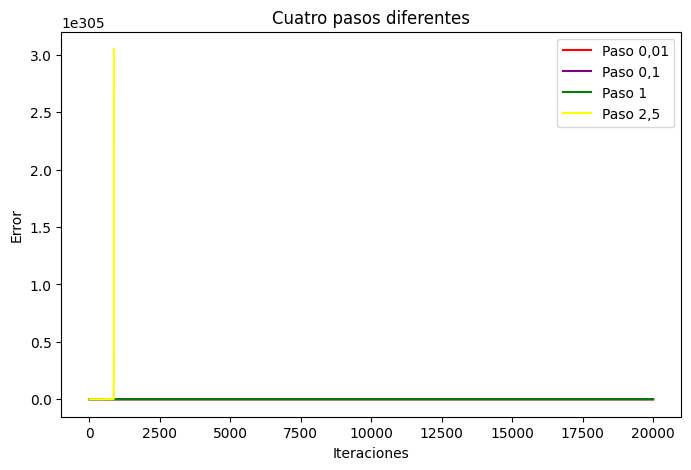

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(iteracion, error_001, color='red', linestyle='-', label='Paso 0,01')
plt.plot(iteracion, error_01, color='purple', linestyle='-', label='Paso 0,1')
plt.plot(iteracion, error_1, color='green', linestyle='-', label='Paso 1')
plt.plot(iteracion, error_25, color='yellow', linestyle='-', label='Paso 2,5')

plt.legend()

plt.xlabel("Iteraciones")
plt.ylabel("Error")

plt.savefig("figuras/cuatro_curvas_error.png", dpi=200)
plt.title("Cuatro pasos diferentes")

Dado que el la línea del paso 2,5 acapara el gráfico, graficamos nuevamente sin incluirla para poder visualizar las demás

Text(0.5, 1.0, 'Tres pasos diferentes')

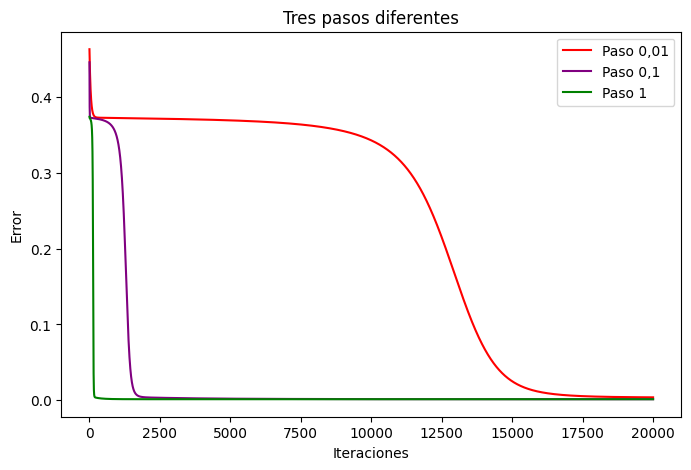

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(iteracion, error_001, color='red', linestyle='-', label='Paso 0,01')
plt.plot(iteracion, error_01, color='purple', linestyle='-', label='Paso 0,1')
plt.plot(iteracion, error_1, color='green', linestyle='-', label='Paso 1')

plt.legend()

plt.xlabel("Iteraciones")
plt.ylabel("Error")

plt.savefig("figuras/tres_curvas_error.png", dpi=200)
plt.title("Tres pasos diferentes")

Cuando el paso es muy grabde, el error aumenta de forma veloz y nunca se acerca al valor esperado, mientras que el paso más pequeño reduce el error lentamente, los pasos más cercanos a 1 parecen ser los que reducen el error a una mayor velocidad

### ii. Distintas inicializaciones

Definimos los valores para 10 inicializaciones distintas en [-1,1]

In [22]:
theta_1 = np.random.uniform(-1, 1, 6)
theta_2 = np.random.uniform(-1, 1, 6)
theta_3 = np.random.uniform(-1, 1, 6)
theta_4 = np.random.uniform(-1, 1, 6)
theta_5 = np.random.uniform(-1, 1, 6)
theta_6 = np.random.uniform(-1, 1, 6)
theta_7 = np.random.uniform(-1, 1, 6)
theta_8 = np.random.uniform(-1, 1, 6)
theta_9 = np.random.uniform(-1, 1, 6)
theta_10 = np.random.uniform(-1, 1, 6)

In [ ]:
#Graficar el error de cada descemso?

Calculamos los descensos de gradiente para cada inicialización

In [23]:
val_20000_a1 = des_gradiente(theta_1, 20000, 1, x, y)
val_20000_a2 = des_gradiente(theta_2, 20000, 1, x, y)
val_20000_a3 = des_gradiente(theta_3, 20000, 1, x, y)
val_20000_a4 = des_gradiente(theta_4, 20000, 1, x, y)
val_20000_a5 = des_gradiente(theta_5, 20000, 1, x, y)
val_20000_a6 = des_gradiente(theta_6, 20000, 1, x, y)
val_20000_a7 = des_gradiente(theta_7, 20000, 1, x, y)
val_20000_a8 = des_gradiente(theta_8, 20000, 1, x, y)
val_20000_a9 = des_gradiente(theta_9, 20000, 1, x, y)
val_20000_a10 = des_gradiente(theta_10, 20000, 1, x, y)

In [24]:
print("Los J para 10 inicializaciones distintad en [-1,1]")
print("El J(θ20.000) de la primera inicialización es", J(val_20000_a1, x, y))
print("El J(θ20.000) de la segunda inicialización es", J(val_20000_a2, x, y))
print("El J(θ20.000) de la tercera inicialización es", J(val_20000_a3, x, y))
print("El J(θ20.000) de la cuarta inicialización es", J(val_20000_a4, x, y))
print("El J(θ20.000) de la quinta inicialización es", J(val_20000_a5, x, y))
print("El J(θ20.000) de la sexta inicialización es", J(val_20000_a6, x, y))
print("El J(θ20.000) de la septima inicialización es", J(val_20000_a7, x, y))
print("El J(θ20.000) de la octava inicialización es", J(val_20000_a8, x, y))
print("El J(θ20.000) de la novena inicialización es", J(val_20000_a9, x, y))
print("El J(θ20.000) de la décima inicialización es", J(val_20000_a10, x, y))

Los J para 10 inicializaciones distintad en [-1,1]
El J(θ20.000) de la primera inicialización es 0.0013955411621448908
El J(θ20.000) de la segunda inicialización es 0.001395355166404074
El J(θ20.000) de la tercera inicialización es 0.0013954968993459397
El J(θ20.000) de la cuarta inicialización es 0.0014107347943005208
El J(θ20.000) de la quinta inicialización es 0.0014059993258779813
El J(θ20.000) de la sexta inicialización es 0.001416276508584076
El J(θ20.000) de la septima inicialización es 0.0014153748402427463
El J(θ20.000) de la octava inicialización es 0.001409257906983144
El J(θ20.000) de la novena inicialización es 0.0014076924339753395
El J(θ20.000) de la décima inicialización es 0.0014149900866107252


Definimos los valores para 10 inicializaciones distintas en [-5,5]

In [25]:
theta_b1 = np.random.uniform(-5, 5, 6)
theta_b2 = np.random.uniform(-5, 5, 6)
theta_b3 = np.random.uniform(-5, 5, 6)
theta_b4 = np.random.uniform(-5, 5, 6)
theta_b5 = np.random.uniform(-5, 5, 6)
theta_b6 = np.random.uniform(-5, 5, 6)
theta_b7 = np.random.uniform(-5, 5, 6)
theta_b8 = np.random.uniform(-5, 5, 6)
theta_b9 = np.random.uniform(-5, 5, 6)
theta_b10 = np.random.uniform(-5, 5, 6)

Calculamos los decensos de gradiente para cada inicialización

In [26]:
val_20000_b1 = des_gradiente(theta_b1, 20000, 1, x, y)
val_20000_b2 = des_gradiente(theta_b2, 20000, 1, x, y)
val_20000_b3 = des_gradiente(theta_b3, 20000, 1, x, y)
val_20000_b4 = des_gradiente(theta_b4, 20000, 1, x, y)
val_20000_b5 = des_gradiente(theta_b5, 20000, 1, x, y)
val_20000_b6 = des_gradiente(theta_b6, 20000, 1, x, y)
val_20000_b7 = des_gradiente(theta_b7, 20000, 1, x, y)
val_20000_b8 = des_gradiente(theta_b8, 20000, 1, x, y)
val_20000_b9 = des_gradiente(theta_b9, 20000, 1, x, y)
val_20000_b10 = des_gradiente(theta_b10, 20000, 1, x, y)

In [27]:
print("Los J para 10 inicializaciones distintad en [-5,5]")
print("El J(θ20.000) de la primera inicialización es", J(val_20000_b1, x, y))
print("El J(θ20.000) de la segunda inicialización es", J(val_20000_b2, x, y))
print("El J(θ20.000) de la tercera inicialización es", J(val_20000_b3, x, y))
print("El J(θ20.000) de la cuarta inicialización es", J(val_20000_b4, x, y))
print("El J(θ20.000) de la quinta inicialización es", J(val_20000_b5, x, y))
print("El J(θ20.000) de la sexta inicialización es", J(val_20000_b6, x, y))
print("El J(θ20.000) de la septima inicialización es", J(val_20000_b7, x, y))
print("El J(θ20.000) de la octava inicialización es", J(val_20000_b8, x, y))
print("El J(θ20.000) de la novena inicialización es", J(val_20000_b9, x, y))
print("El J(θ20.000) de la décima inicialización es", J(val_20000_b10, x, y))

Los J para 10 inicializaciones distintad en [-5,5]
El J(θ20.000) de la primera inicialización es 0.0014451338507139248
El J(θ20.000) de la segunda inicialización es 0.0013924007734941698
El J(θ20.000) de la tercera inicialización es 0.0013988754077034768
El J(θ20.000) de la cuarta inicialización es 0.0014085433050804988
El J(θ20.000) de la quinta inicialización es 0.0014211774414186044
El J(θ20.000) de la sexta inicialización es 0.001479627709811132
El J(θ20.000) de la septima inicialización es 0.37248297413788406
El J(θ20.000) de la octava inicialización es 0.001400460223499488
El J(θ20.000) de la novena inicialización es 0.0014261599687102303
El J(θ20.000) de la décima inicialización es 0.0013918742850255864


En ambos casos los resultados de J son similares, incluso iguales hasta la centésima por lo que podemos afirmar que aproximan similarmente a pesar que no alcanzar valores iguales, sin embargo [-5,5] presenta errores mayores, lo que se debe a que al tener un |t| grande la función σ′(t) se asemeja demasiado a cero lo que afecta a la resta en el cálculo de la gradiente, evitando que el valor varíe adecuadamente

## (g) Datos de otra función

### i. Entrenamiento con `datos_P2_g.csv`

Primero se entrena la red con los nuevos datos.

In [28]:
val_20000_g = des_gradiente(theta_0, 20000, 1, x_g, y_g)
print("θ20.000 para los nuevos datos es", val_20000_g)
print("El error J(θ20.000) para los nuevos datos es", J(val_20000_g, x_g, y_g))

θ20.000 para los nuevos datos es [np.float64(8.401351626247376), np.float64(-0.5626490218605257), np.float64(8.243239896679023), np.float64(0.19747553203330392), np.float64(2.2280268751029895), np.float64(-1.0406181529188971)]
El error J(θ20.000) para los nuevos datos es 0.07819064962371876


Luego, generamos nuevos 200 valores en el rango [-1, 1]

In [29]:
x_plot_g = np.linspace(-1, 1, 200)

a1_g, b1_g, a2_g, b2_g, v_g, c_g = val_20000_g

h1_plot_g = sigma(a1_g * x_plot_g + b1_g)
h2_plot_g = sigma(a2_g * h1_plot_g + b2_g)

Aquí definimos los resultados de nuestra red "$\hat{y}$", donde por temas de comparativa usaremos nuestros 200 nuevos valores, como también las aproximaciones a nuestros datos originales g

In [30]:
y_hat_plot_g_new = v_g * h2_plot_g + c_g

In [31]:
aproximaciones_g = []
for i in range(len(x_g)):
    aproximaciones_g.append(y_gorrito(i, val_20000_g, x_g))
y_hat_plot_g = np.array(aproximaciones_g)

Graficamos con scatter las aproximaciones a nuestros valores de g

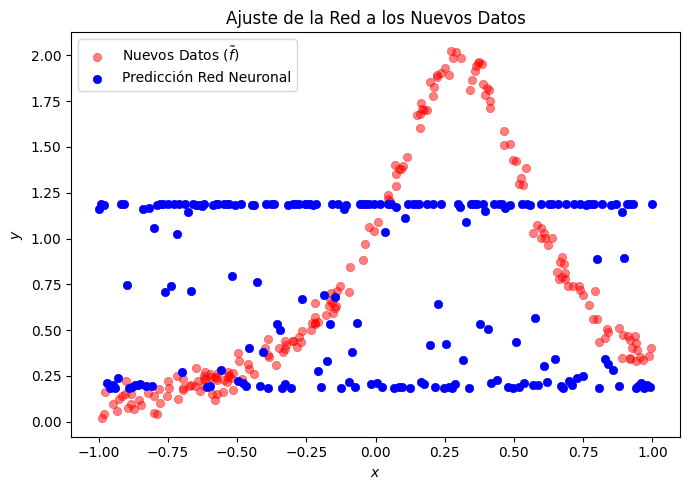

In [32]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x_g, y_g, color='red', alpha=0.5, linewidth=0.5, label='Nuevos Datos ($\\tilde{f}$)')
ax.scatter(x_plot_g, y_hat_plot_g, color='blue', linewidth=0.5, label='Predicción Red Neuronal')
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Ajuste de la Red a los Nuevos Datos")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/ajuste_datos_g.png", dpi=200)
plt.show()

Y de manera lineal nuestros nuevos valores

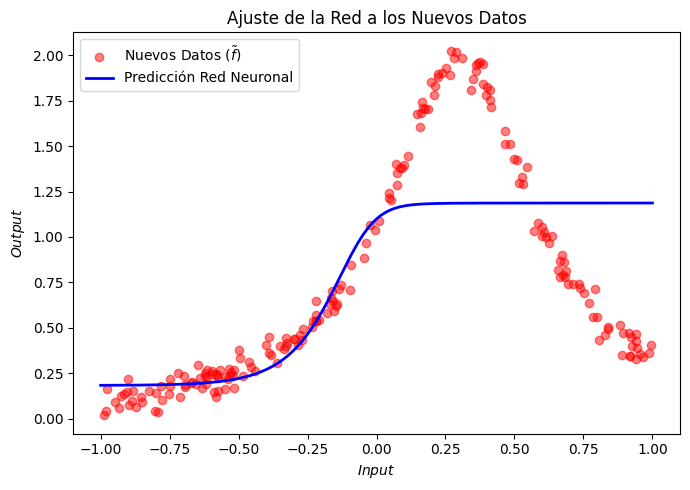

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x_g, y_g, color='red', alpha=0.5, label='Nuevos Datos ($\\tilde{f}$)')
ax.plot(x_plot_g, y_hat_plot_g_new, color='blue', linewidth=2, label='Predicción Red Neuronal')
ax.set_xlabel("$Input$")
ax.set_ylabel("$Output$")
ax.set_title("Ajuste de la Red a los Nuevos Datos")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/ajuste_datos_g.png", dpi=200)
plt.show()

### ii.

(Explicación de informe, pero como no hay, va aquí de mientras 😛)

**1. Demostración de monotonía de $\hat{y}(x;\theta)$**

Sabemos por la definición de la red que la función de predicción es:
$$ \hat{y}(x; \theta) = c + v \cdot \sigma(a_2 \cdot \sigma(a_1x + b_1) + b_2) $$

Si derivamos $\hat{y}$ con respecto a $x$ aplicando la regla de la cadena (como se calculó en el inciso b), obtenemos:
$$ \frac{d\hat{y}}{dx} = v \cdot \sigma'(z_2) \cdot a_2 \cdot \sigma'(z_1) \cdot a_1 $$
*(Donde $z_1 = a_1x + b_1$ y $z_2 = a_2\sigma(z_1) + b_2$)*.

En el inciso (a) demostramos que la derivada de la función sigmoide es siempre estrictamente positiva ($0 < \sigma'(t) \le \frac{1}{4}$). Dado que $\sigma'(z_1) > 0$ y $\sigma'(z_2) > 0$ para cualquier valor de $x$, el signo de la derivada $\frac{d\hat{y}}{dx}$ depende exclusivamente del producto de los parámetros constantes: $(v \cdot a_2 \cdot a_1)$.

Dado que $v, a_2$ y $a_1$ son constantes fijas para un $\theta$ dado, su producto no puede cambiar de signo. En consecuencia, la derivada no cambia de signo en todo $\mathbb{R}$, lo que demuestra que la función $x \mapsto \hat{y}(x;\theta)$ es **estrictamente monótona** (siempre creciente o siempre decreciente dependiendo del signo del producto $v \cdot a_2 \cdot a_1$).

**2. Demostración de los límites de la salida**

La última capa de la red neuronal está definida como:
$$ \hat{y} = c + v \cdot h_2 $$
Donde $h_2 = \sigma(z_2)$. 

Sabemos que el recorrido de la función de activación sigmoide es estrictamente el intervalo abierto $(0, 1)$. Por lo tanto, $0 < h_2 < 1$. 
Si evaluamos los casos extremos para $h_2$:
* Cuando $h_2 \to 0$, $\hat{y} \to c + v(0) = c$.
* Cuando $h_2 \to 1$, $\hat{y} \to c + v(1) = c + v$.

De esto concluimos que, independientemente del valor de entrada $x$ o de los parámetros $\theta$, la predicción de la red $\hat{y}$ está siempre **acotada** en el intervalo comprendido entre $c$ y $c+v$.

**3. Conclusión sobre el ajuste a los nuevos datos $\tilde{f}$**

Al observar el gráfico de dispersión del inciso (g.i), los nuevos datos $\tilde{f}$ tienen un comportamiento claramente **no monótono** en el intervalo $[-1, 1]$ (la curva sube hasta formar un pico y luego desciende). 

Como se demostró en los puntos anteriores, la arquitectura de esta red neuronal específica (dos capas ocultas con una sola neurona cada una) solo tiene la capacidad matemática de representar funciones que sean **estrictamente monótonas y acotadas**. 

Debido a esta limitación estructural, la red es incapaz de "doblarse" para reflejar subidas y bajadas. Por lo tanto, es matemáticamente imposible que esta red se ajuste de forma correcta a la función $\tilde{f}$, sin importar cuántas iteraciones se realicen en el entrenamiento, el tamaño del paso ($\alpha$) elegido o los valores de inicialización ($\theta_0$).